In [10]:
# # Install dependencies as needed:
# python -m pip install pandas matplotlib seaborn jupyter
# pip install kagglehub[pandas-datasets]
import pandas as pd
%matplotlib
import matplotlib as mpl
import seaborn as sns
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_selector
from sklearn.compose import make_column_transformer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score
from sklearn import metrics
from sklearn.metrics import confusion_matrix



Using matplotlib backend: module://matplotlib_inline.backend_inline


In [12]:
df = pd.read_csv('/home/matthieumouillon/projects/app-streamlit/weather.csv')
df.head(1)

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
0,8.0,24.3,0.0,3.4,6.3,NW,30.0,SW,NW,6.0,...,29,1019.7,1015.0,7,7,14.4,23.6,No,3.6,Yes


In [ ]:
import random

villes = ["Paris", "Lyon", "Marseille", "Biarritz"]

def df_villes_choisies(ville):
    return random.choice(ville)
 


In [ ]:
df["villes"] = ""
for index in df.index:
    df.at[index, "villes"] = df_villes_choisies(villes)
    

In [ ]:
df.head(3)

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,...,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow,villes
0,8.0,24.3,0.0,3.4,6.3,NW,30.0,SW,NW,6.0,...,1019.7,1015.0,7,7,14.4,23.6,No,3.6,Yes,Paris
1,14.0,26.9,3.6,4.4,9.7,ENE,39.0,E,W,4.0,...,1012.4,1008.4,5,3,17.5,25.7,Yes,3.6,Yes,Biarritz
2,13.7,23.4,3.6,5.8,3.3,NW,85.0,N,NNE,6.0,...,1009.5,1007.2,8,7,15.4,20.2,Yes,39.8,Yes,Paris


In [ ]:
df.shape

(366, 22)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MinTemp        366 non-null    float64
 1   MaxTemp        366 non-null    float64
 2   Rainfall       366 non-null    float64
 3   Evaporation    366 non-null    float64
 4   Sunshine       363 non-null    float64
 5   WindGustDir    363 non-null    object 
 6   WindGustSpeed  364 non-null    float64
 7   WindDir9am     335 non-null    object 
 8   WindDir3pm     365 non-null    object 
 9   WindSpeed9am   359 non-null    float64
 10  WindSpeed3pm   366 non-null    int64  
 11  Humidity9am    366 non-null    int64  
 12  Humidity3pm    366 non-null    int64  
 13  Pressure9am    366 non-null    float64
 14  Pressure3pm    366 non-null    float64
 15  Cloud9am       366 non-null    int64  
 16  Cloud3pm       366 non-null    int64  
 17  Temp9am        366 non-null    float64
 18  Temp3pm   

In [ ]:
df.columns.to_frame

<bound method Index.to_frame of Index(['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
       'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm',
       'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm',
       'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am',
       'Temp3pm', 'RainToday', 'RISK_MM', 'RainTomorrow'],
      dtype='object')>

<Axes: >

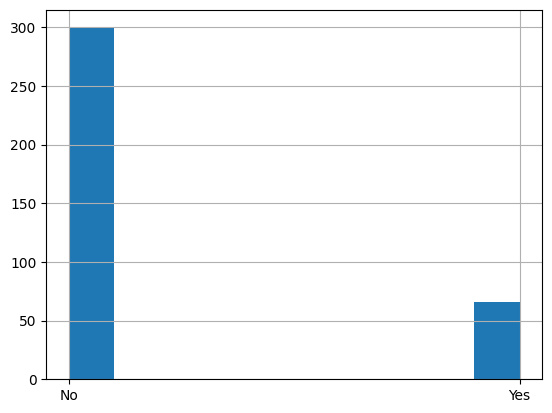

In [ ]:
df['RainToday'].hist()

In [ ]:
df["RainToday"] = df["RainToday"].map({"Yes": 1, "No": 0})
df["RainTomorrow"] = df["RainTomorrow"].map({"Yes": 1, "No": 0})

In [ ]:
print(df.iloc[0])

MinTemp             8.0
MaxTemp            24.3
Rainfall            0.0
Evaporation         3.4
Sunshine            6.3
WindGustDir          NW
WindGustSpeed      30.0
WindDir9am           SW
WindDir3pm           NW
WindSpeed9am        6.0
WindSpeed3pm         20
Humidity9am          68
Humidity3pm          29
Pressure9am      1019.7
Pressure3pm      1015.0
Cloud9am              7
Cloud3pm              7
Temp9am            14.4
Temp3pm            23.6
RainToday             0
RISK_MM             3.6
RainTomorrow          1
Name: 0, dtype: object


In [ ]:
#avec entêtes de colonnes
print(df.iloc[[0]])

   MinTemp  MaxTemp  Rainfall  Evaporation  Sunshine WindGustDir  \
0      8.0     24.3       0.0          3.4       6.3          NW   

   WindGustSpeed WindDir9am WindDir3pm  WindSpeed9am  ...  Humidity3pm  \
0           30.0         SW         NW           6.0  ...           29   

   Pressure9am  Pressure3pm  Cloud9am  Cloud3pm  Temp9am  Temp3pm  RainToday  \
0       1019.7       1015.0         7         7     14.4     23.6          0   

   RISK_MM  RainTomorrow  
0      3.6             1  

[1 rows x 22 columns]


In [ ]:
df.head(5)

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
0,8.0,24.3,0.0,3.4,6.3,NW,30.0,SW,NW,6.0,...,29,1019.7,1015.0,7,7,14.4,23.6,0,3.6,1
1,14.0,26.9,3.6,4.4,9.7,ENE,39.0,E,W,4.0,...,36,1012.4,1008.4,5,3,17.5,25.7,1,3.6,1
2,13.7,23.4,3.6,5.8,3.3,NW,85.0,N,NNE,6.0,...,69,1009.5,1007.2,8,7,15.4,20.2,1,39.8,1
3,13.3,15.5,39.8,7.2,9.1,NW,54.0,WNW,W,30.0,...,56,1005.5,1007.0,2,7,13.5,14.1,1,2.8,1
4,7.6,16.1,2.8,5.6,10.6,SSE,50.0,SSE,ESE,20.0,...,49,1018.3,1018.5,7,7,11.1,15.4,1,0.0,0


In [ ]:
X=df[['MinTemp','MaxTemp','Rainfall','Evaporation','Sunshine','WindGustSpeed','WindSpeed9am', 'Humidity3pm','Pressure9am','Pressure3pm','Cloud9am','Cloud3pm', 'Temp9am','Temp3pm','RainToday']]

In [ ]:
y=df['RainTomorrow']

In [ ]:
# Exclude rows whose target is missing, if any
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows]

In [ ]:
print("Cibles manquantes :", y.isna().sum())

Cibles manquantes : 0


In [ ]:
corr_matrix = X.corr()

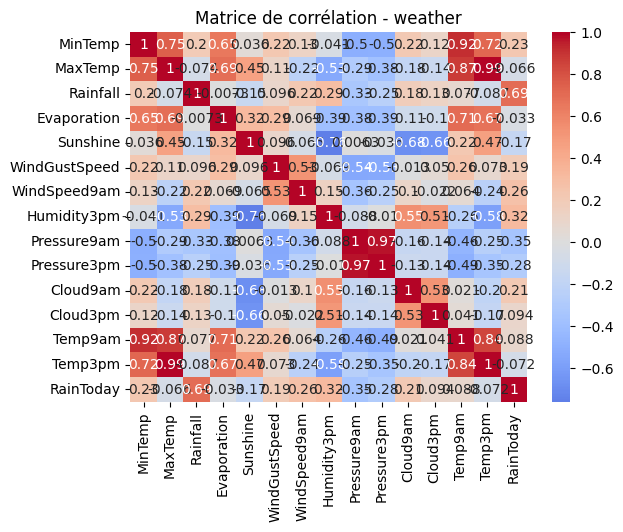

In [ ]:
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
plt.title("Matrice de corrélation - weather")
plt.show()


**OBSERVATION / Correlation is strong between MinTemp and Temp9am**

<Axes: xlabel='MinTemp', ylabel='Temp9am'>

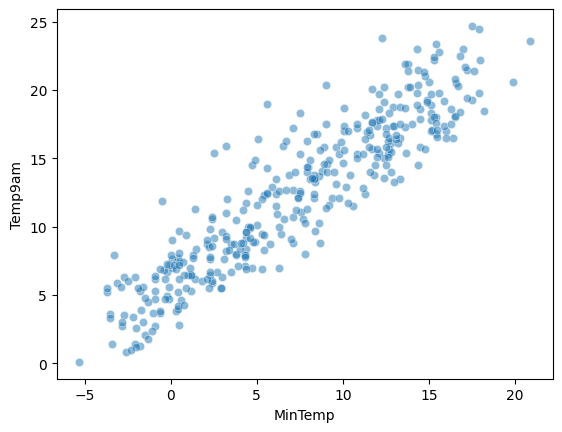

In [ ]:
sns.scatterplot(data=df, x=df['MinTemp'], y=df['Temp9am'], alpha=0.5)


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
num_pipe_preprocessing = Pipeline([
    ('imput', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler()),
     ])

In [ ]:
preprocessor_application = ColumnTransformer([
    ('num_pipe', num_pipe_preprocessing, make_column_selector(dtype_exclude='object'))
])


In [ ]:
X_train_transformed = preprocessor_application.fit_transform(X_train)
X_test_transformed = preprocessor_application.transform(X_test)


In [ ]:
model=LogisticRegression()
model.fit(X_train_transformed, y_train)
y_pred = model.predict(X_test_transformed)

In [ ]:
# preprocessor = ColumnTransformer([
#     ("num", Pipeline([
#         ("imputer", SimpleImputer(strategy="mean")),
#         ("scaler", StandardScaler()),
#     ]), make_column_selector(dtype_include="number"))
# ])

# model = Pipeline([
#     ("preprocessor", preprocessor),
#     ("classifier", LogisticRegression(max_iter=1000)),
# ])

# model.fit(X_train, y_train)
# y_pred = model.predict(X_test)

In [ ]:
new_datapoint= pd.DataFrame({
    'MinTemp':[8],
    'MaxTemp':[24.3],
    'Rainfall':[0.0],
    'Evaporation':[3.4],
    'Sunshine':[6.3],
    'WindGustSpeed':[30.0],
    'WindSpeed9am':[6.0],
    'Humidity3pm':[29],
    'Pressure9am':[1019.7],
    'Pressure3pm':[1015.0],
    'Cloud9am':[7],
    'Cloud3pm':[7],
    'Temp9am':[14.4],
    'Temp3pm':[23.6],
    'RainToday':[0]}
    
    
    )

In [ ]:
df.head(1)

In [ ]:
print(model.classes_)

[0 1]


In [ ]:
new_datapoint_transformed = preprocessor_application.transform(new_datapoint)

print(model.predict(new_datapoint_transformed))
print(model.predict_proba(new_datapoint_transformed))

[0]
[[0.85250552 0.14749448]]


**CONCLUSION**

**Présentation du modèle choisi** : *Pour les caractéristiques météorologiques renseignées, le modèle estime une probabilité de pluie demain de 14,7 %, contre 85,3 % de probabilité d’absence de pluie. Il est donc probable qu'il ne pleuve pas selon le seuil de décision choisi, un modèle léinaire de régression logistique qui se traduit par une approche sigmoïdale (oui OU non ici traduit en 1 et 0).* 

**Résultats commentés** : Toutefois, la prédiction peut sembler surprenant, puisque nous avons utilisé des valeurs existantes ( ligne 1 du dataframe). La valeur attendue était 1(=pluie) qui correspondait à la valeur réellement observée. Tandis que le résultat est 0 (pas de pluie). 
**Par conséquent, le modèle s’est donc trompé sur cet exemple. Cela peut arriver, car il s’agit d’une estimation statistique et non d’une certitude.** 

*Ce résultat montre que le modèle ne détecte pas correctement tous les épisodes pluvieux et qu’il faut évaluer ses performances sur un ensemble de tests, notamment à l’aide de la matrice de confusion et du rappel pour la classe « pluie ».*

###### ------------------------------------------------------------------------------------------------------------------

En complément pour moi - aide mémoire
.iloc et .loc servent tous deux à sélectionner des lignes et des colonnes. La différence est le type d’index utilisé :
.iloc sélectionne par position numérique (à partir de 0).
.loc sélectionne par étiquette (nom de ligne ou de colonne).

In [ ]:
df.iloc[0]        # première ligne ou df.iloc[0,:] 
df.iloc[:, 0]     # première colonne
df.loc[0]         # ligne dont l'étiquette d'index est 0
df.loc[:, "RainToday"]  # colonne nommée RainToday

0      0
1      1
2      1
3      1
4      1
      ..
361    0
362    0
363    0
364    0
365    0
Name: RainToday, Length: 366, dtype: int64